<a href="https://colab.research.google.com/github/abdulrafaykhan11/Laptop-Price-Predictions/blob/main/Laptop_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [94]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


In [95]:
df = pd.read_csv("laptop_price.csv",encoding='latin1')

In [96]:
df

,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,1339.69
1,2,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,2537.45
4,5,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,1803.60
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,1316,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,638.00
1299,1317,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,1499.00
1300,1318,Lenovo,IdeaPad 100S-14IBR,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,229.00
1301,1319,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,764.00


In [97]:
df.shape

(1303, 13)

In [98]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   laptop_ID         1303 non-null   int64  
 1   Company           1303 non-null   object 
 2   Product           1303 non-null   object 
 3   TypeName          1303 non-null   object 
 4   Inches            1303 non-null   float64
 5   ScreenResolution  1303 non-null   object 
 6   Cpu               1303 non-null   object 
 7   Ram               1303 non-null   object 
 8   Memory            1303 non-null   object 
 9   Gpu               1303 non-null   object 
 10  OpSys             1303 non-null   object 
 11  Weight            1303 non-null   object 
 12  Price_euros       1303 non-null   float64
dtypes: float64(2), int64(1), object(10)
memory usage: 132.5+ KB


In [99]:
df.drop(columns=['laptop_ID'],inplace=True)

In [100]:
df['Ram'] = df['Ram'].str.replace('GB','').astype(int)

In [101]:
df['Weight'] = df['Weight'].str.replace('kg','').astype('float32')

In [102]:
df.rename(columns={'Ram' : 'Ram_GB','Weight' : 'Weight_kg'})

,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram_GB,Memory,Gpu,OpSys,Weight_kg,Price_euros
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60
...,...,...,...,...,...,...,...,...,...,...,...,...
1298,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4,128GB SSD,Intel HD Graphics 520,Windows 10,1.80,638.00
1299,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16,512GB SSD,Intel HD Graphics 520,Windows 10,1.30,1499.00
1300,Lenovo,IdeaPad 100S-14IBR,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2,64GB Flash Storage,Intel HD Graphics,Windows 10,1.50,229.00
1301,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19,764.00


In [103]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1303 non-null   object 
 1   Product           1303 non-null   object 
 2   TypeName          1303 non-null   object 
 3   Inches            1303 non-null   float64
 4   ScreenResolution  1303 non-null   object 
 5   Cpu               1303 non-null   object 
 6   Ram               1303 non-null   int64  
 7   Memory            1303 non-null   object 
 8   Gpu               1303 non-null   object 
 9   OpSys             1303 non-null   object 
 10  Weight            1303 non-null   float32
 11  Price_euros       1303 non-null   float64
dtypes: float32(1), float64(2), int64(1), object(8)
memory usage: 117.2+ KB


In [104]:
df['ScreenResolution'].unique()

array(['IPS Panel Retina Display 2560x1600', '1440x900',
       'Full HD 1920x1080', 'IPS Panel Retina Display 2880x1800',
       '1366x768', 'IPS Panel Full HD 1920x1080',
       'IPS Panel Retina Display 2304x1440',
       'IPS Panel Full HD / Touchscreen 1920x1080',
       'Full HD / Touchscreen 1920x1080',
       'Touchscreen / Quad HD+ 3200x1800',
       'IPS Panel Touchscreen 1920x1200', 'Touchscreen 2256x1504',
       'Quad HD+ / Touchscreen 3200x1800', 'IPS Panel 1366x768',
       'IPS Panel 4K Ultra HD / Touchscreen 3840x2160',
       'IPS Panel Full HD 2160x1440',
       '4K Ultra HD / Touchscreen 3840x2160', 'Touchscreen 2560x1440',
       '1600x900', 'IPS Panel 4K Ultra HD 3840x2160',
       '4K Ultra HD 3840x2160', 'Touchscreen 1366x768',
       'IPS Panel Full HD 1366x768', 'IPS Panel 2560x1440',
       'IPS Panel Full HD 2560x1440',
       'IPS Panel Retina Display 2736x1824', 'Touchscreen 2400x1600',
       '2560x1440', 'IPS Panel Quad HD+ 2560x1440',
       'IPS Panel 

In [105]:
touchscreen = []
for i in df['ScreenResolution']:
    if 'Touchscreen' in i:
        touchscreen.append(1)
    else:
        touchscreen.append(0)

In [106]:
df['Touch_Screen'] = touchscreen

In [107]:
df

,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros,Touch_Screen
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4,128GB SSD,Intel HD Graphics 520,Windows 10,1.80,638.00,1
1299,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16,512GB SSD,Intel HD Graphics 520,Windows 10,1.30,1499.00,1
1300,Lenovo,IdeaPad 100S-14IBR,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2,64GB Flash Storage,Intel HD Graphics,Windows 10,1.50,229.00,0
1301,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19,764.00,0


In [108]:
ips = []
for i in df['ScreenResolution']:
  if 'IPS Panel' in i:
    ips.append(1)
  else:
    ips.append(0)

In [109]:
df['IPS'] = ips

In [110]:
df

,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros,Touch_Screen,IPS
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0,0
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0,0
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,14.0,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4,128GB SSD,Intel HD Graphics 520,Windows 10,1.80,638.00,1,1
1299,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16,512GB SSD,Intel HD Graphics 520,Windows 10,1.30,1499.00,1,1
1300,Lenovo,IdeaPad 100S-14IBR,Notebook,14.0,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2,64GB Flash Storage,Intel HD Graphics,Windows 10,1.50,229.00,0,0
1301,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19,764.00,0,0


In [111]:
new = df['ScreenResolution'].str.split('x', n=1, expand=True)

df['X_res'] = new[0]
df['Y_res'] = new[1]

df['X_res'] = (
    df['X_res']
    .str.replace(',', '')
    .str.findall(r'(\d+\.?\d+)')
    .apply(lambda x: x[0])
)

df['X_res'] = df['X_res'].astype('int')
df['Y_res'] = df['Y_res'].astype('int')


df['ppi'] = (
    ((df['X_res'] ** 2) + (df['Y_res'] ** 2)) ** 0.5 / df['Inches']
).astype('float')

df.drop(columns=['ScreenResolution', 'Inches', 'X_res', 'Y_res'], inplace=True)

In [112]:
df

,Company,Product,TypeName,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros,Touch_Screen,IPS,ppi
0,Apple,MacBook Pro,Ultrabook,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005
1,Apple,Macbook Air,Ultrabook,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940
2,HP,250 G6,Notebook,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998
3,Apple,MacBook Pro,Ultrabook,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624
4,Apple,MacBook Pro,Ultrabook,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,Intel Core i7 6500U 2.5GHz,4,128GB SSD,Intel HD Graphics 520,Windows 10,1.80,638.00,1,1,157.350512
1299,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,Intel Core i7 6500U 2.5GHz,16,512GB SSD,Intel HD Graphics 520,Windows 10,1.30,1499.00,1,1,276.053530
1300,Lenovo,IdeaPad 100S-14IBR,Notebook,Intel Celeron Dual Core N3050 1.6GHz,2,64GB Flash Storage,Intel HD Graphics,Windows 10,1.50,229.00,0,0,111.935204
1301,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,Intel Core i7 6500U 2.5GHz,6,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19,764.00,0,0,100.454670


In [113]:
df.rename(columns={'ppi':'PPI'},inplace=True)

In [114]:
df

,Company,Product,TypeName,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros,Touch_Screen,IPS,PPI
0,Apple,MacBook Pro,Ultrabook,Intel Core i5 2.3GHz,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005
1,Apple,Macbook Air,Ultrabook,Intel Core i5 1.8GHz,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940
2,HP,250 G6,Notebook,Intel Core i5 7200U 2.5GHz,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998
3,Apple,MacBook Pro,Ultrabook,Intel Core i7 2.7GHz,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624
4,Apple,MacBook Pro,Ultrabook,Intel Core i5 3.1GHz,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,Intel Core i7 6500U 2.5GHz,4,128GB SSD,Intel HD Graphics 520,Windows 10,1.80,638.00,1,1,157.350512
1299,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,Intel Core i7 6500U 2.5GHz,16,512GB SSD,Intel HD Graphics 520,Windows 10,1.30,1499.00,1,1,276.053530
1300,Lenovo,IdeaPad 100S-14IBR,Notebook,Intel Celeron Dual Core N3050 1.6GHz,2,64GB Flash Storage,Intel HD Graphics,Windows 10,1.50,229.00,0,0,111.935204
1301,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,Intel Core i7 6500U 2.5GHz,6,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19,764.00,0,0,100.454670


In [115]:
# 1. Clock Speed (GHz) nikalna
df['Cpu_speed'] = df['Cpu'].apply(lambda x: float(x.split()[-1].replace('GHz', '')))

# 2. CPU Name ke pehle 3 words nikalna (e.g., "Intel Core i5")
df['Cpu_name'] = df['Cpu'].apply(lambda x: " ".join(x.split()[0:3]))

# 3. CPU Brands ko categorize karna
def fetch_processor(text):
    if text in ['Intel Core i7', 'Intel Core i5', 'Intel Core i3']:
        return text
    elif text.split()[0] == 'Intel':
        return 'Other Intel Processor'
    else:
        return 'AMD Processor'

df['Cpu_brand'] = df['Cpu_name'].apply(fetch_processor)

# Purane extra columns drop karna
df.drop(columns=['Cpu', 'Cpu_name'], inplace=True)


In [116]:
df

,Company,Product,TypeName,Ram,Memory,Gpu,OpSys,Weight,Price_euros,Touch_Screen,IPS,PPI,Cpu_speed,Cpu_brand
0,Apple,MacBook Pro,Ultrabook,8,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37,1339.69,0,1,226.983005,2.3,Intel Core i5
1,Apple,Macbook Air,Ultrabook,8,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34,898.94,0,0,127.677940,1.8,Intel Core i5
2,HP,250 G6,Notebook,8,256GB SSD,Intel HD Graphics 620,No OS,1.86,575.00,0,0,141.211998,2.5,Intel Core i5
3,Apple,MacBook Pro,Ultrabook,16,512GB SSD,AMD Radeon Pro 455,macOS,1.83,2537.45,0,1,220.534624,2.7,Intel Core i7
4,Apple,MacBook Pro,Ultrabook,8,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37,1803.60,0,1,226.983005,3.1,Intel Core i5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,4,128GB SSD,Intel HD Graphics 520,Windows 10,1.80,638.00,1,1,157.350512,2.5,Intel Core i7
1299,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,16,512GB SSD,Intel HD Graphics 520,Windows 10,1.30,1499.00,1,1,276.053530,2.5,Intel Core i7
1300,Lenovo,IdeaPad 100S-14IBR,Notebook,2,64GB Flash Storage,Intel HD Graphics,Windows 10,1.50,229.00,0,0,111.935204,1.6,Other Intel Processor
1301,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,6,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19,764.00,0,0,100.454670,2.5,Intel Core i7


In [117]:
# Clean string aur TB ko 1000 mein convert karna
df['Memory'] = df['Memory'].astype(str).replace('\.0', '', regex=True)
df['Memory'] = df['Memory'].str.replace('GB', '')
df['Memory'] = df['Memory'].str.replace('TB', '000')

# '+' ke hisaab se do hisson mein split karna
new = df['Memory'].str.split('+', n=1, expand=True)

df['first'] = new[0].str.strip()
df['second'] = new[1].fillna('0').str.strip()

# Pehle hisse (first) se storage type pehchanna
df['Layer1HDD'] = df['first'].apply(lambda x: 1 if 'HDD' in x else 0)
df['Layer1SSD'] = df['first'].apply(lambda x: 1 if 'SSD' in x else 0)
df['Layer1Hybrid'] = df['first'].apply(lambda x: 1 if 'Hybrid' in x else 0)
df['Layer1Flash_Storage'] = df['first'].apply(lambda x: 1 if 'Flash Storage' in x else 0)

# Doosre hisse (second) se storage type pehchanna
df['Layer2HDD'] = df['second'].apply(lambda x: 1 if 'HDD' in x else 0)
df['Layer2SSD'] = df['second'].apply(lambda x: 1 if 'SSD' in x else 0)
df['Layer2Hybrid'] = df['second'].apply(lambda x: 1 if 'Hybrid' in x else 0)
df['Layer2Flash_Storage'] = df['second'].apply(lambda x: 1 if 'Flash Storage' in x else 0)

# Sirf numbers rakhna (text hatana)
df['first'] = df['first'].str.replace(r'\D', '', regex=True).astype(int)
df['second'] = df['second'].str.replace(r'\D', '', regex=True).astype(int)

# Final 4 numeric columns (GB mein) banana
df['HDD'] = (df['first'] * df['Layer1HDD'] + df['second'] * df['Layer2HDD'])
df['SSD'] = (df['first'] * df['Layer1SSD'] + df['second'] * df['Layer2SSD'])
df['Hybrid'] = (df['first'] * df['Layer1Hybrid'] + df['second'] * df['Layer2Hybrid'])
df['Flash_Storage'] = (df['first'] * df['Layer1Flash_Storage'] + df['second'] * df['Layer2Flash_Storage'])

# Sabhi temporary aur purane columns drop karna
df.drop(columns=[
    'Memory', 'first', 'second',
    'Layer1HDD', 'Layer1SSD', 'Layer1Hybrid', 'Layer1Flash_Storage',
    'Layer2HDD', 'Layer2SSD', 'Layer2Hybrid', 'Layer2Flash_Storage'
], inplace=True)


In [118]:
# Pehla word extract karna
df['Gpu_brand'] = df['Gpu'].apply(lambda x: x.split()[0])

# Agar dataset mein 'ARM' GPU wali 1-2 rows hon to unhe hata dena (optional, model stability ke liye accha hai)
df = df[df['Gpu_brand'] != 'ARM']

# Purana column drop karna
df.drop(columns=['Gpu'], inplace=True)


In [119]:
def cat_os(os):
    if os in ['Windows 10', 'Windows 7', 'Windows 10 S']:
        return 'Windows'
    elif os in ['macOS', 'Mac OS X']:
        return 'Mac'
    else:
        return 'Others/No OS/Linux'

df['OS'] = df['OpSys'].apply(cat_os)

# Purana column drop karna
df.drop(columns=['OpSys'], inplace=True)


In [120]:
df

,Company,Product,TypeName,Ram,Weight,Price_euros,Touch_Screen,IPS,PPI,Cpu_speed,Cpu_brand,HDD,SSD,Hybrid,Flash_Storage,Gpu_brand,OS
0,Apple,MacBook Pro,Ultrabook,8,1.37,1339.69,0,1,226.983005,2.3,Intel Core i5,0,128,0,0,Intel,Mac
1,Apple,Macbook Air,Ultrabook,8,1.34,898.94,0,0,127.677940,1.8,Intel Core i5,0,0,0,128,Intel,Mac
2,HP,250 G6,Notebook,8,1.86,575.00,0,0,141.211998,2.5,Intel Core i5,0,256,0,0,Intel,Others/No OS/Linux
3,Apple,MacBook Pro,Ultrabook,16,1.83,2537.45,0,1,220.534624,2.7,Intel Core i7,0,512,0,0,AMD,Mac
4,Apple,MacBook Pro,Ultrabook,8,1.37,1803.60,0,1,226.983005,3.1,Intel Core i5,0,256,0,0,Intel,Mac
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,4,1.80,638.00,1,1,157.350512,2.5,Intel Core i7,0,128,0,0,Intel,Windows
1299,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,16,1.30,1499.00,1,1,276.053530,2.5,Intel Core i7,0,512,0,0,Intel,Windows
1300,Lenovo,IdeaPad 100S-14IBR,Notebook,2,1.50,229.00,0,0,111.935204,1.6,Other Intel Processor,0,0,0,64,Intel,Windows
1301,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,6,2.19,764.00,0,0,100.454670,2.5,Intel Core i7,1000,0,0,0,AMD,Windows


<Axes: >

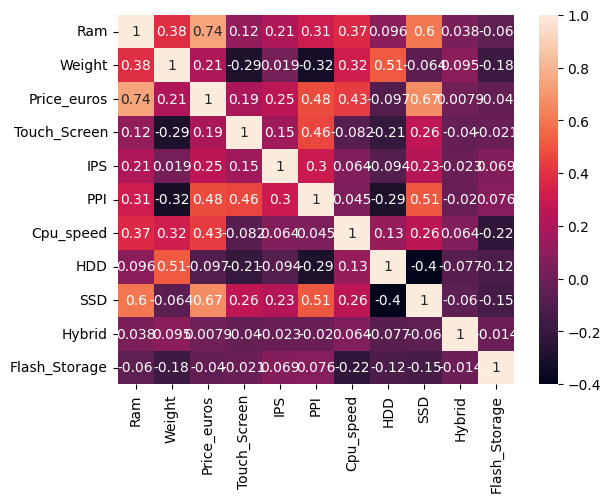

In [121]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [122]:
df

,Company,Product,TypeName,Ram,Weight,Price_euros,Touch_Screen,IPS,PPI,Cpu_speed,Cpu_brand,HDD,SSD,Hybrid,Flash_Storage,Gpu_brand,OS
0,Apple,MacBook Pro,Ultrabook,8,1.37,1339.69,0,1,226.983005,2.3,Intel Core i5,0,128,0,0,Intel,Mac
1,Apple,Macbook Air,Ultrabook,8,1.34,898.94,0,0,127.677940,1.8,Intel Core i5,0,0,0,128,Intel,Mac
2,HP,250 G6,Notebook,8,1.86,575.00,0,0,141.211998,2.5,Intel Core i5,0,256,0,0,Intel,Others/No OS/Linux
3,Apple,MacBook Pro,Ultrabook,16,1.83,2537.45,0,1,220.534624,2.7,Intel Core i7,0,512,0,0,AMD,Mac
4,Apple,MacBook Pro,Ultrabook,8,1.37,1803.60,0,1,226.983005,3.1,Intel Core i5,0,256,0,0,Intel,Mac
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1298,Lenovo,Yoga 500-14ISK,2 in 1 Convertible,4,1.80,638.00,1,1,157.350512,2.5,Intel Core i7,0,128,0,0,Intel,Windows
1299,Lenovo,Yoga 900-13ISK,2 in 1 Convertible,16,1.30,1499.00,1,1,276.053530,2.5,Intel Core i7,0,512,0,0,Intel,Windows
1300,Lenovo,IdeaPad 100S-14IBR,Notebook,2,1.50,229.00,0,0,111.935204,1.6,Other Intel Processor,0,0,0,64,Intel,Windows
1301,HP,15-AC110nv (i7-6500U/6GB/1TB/Radeon,Notebook,6,2.19,764.00,0,0,100.454670,2.5,Intel Core i7,1000,0,0,0,AMD,Windows


In [123]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1302 entries, 0 to 1302
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Company        1302 non-null   object 
 1   Product        1302 non-null   object 
 2   TypeName       1302 non-null   object 
 3   Ram            1302 non-null   int64  
 4   Weight         1302 non-null   float32
 5   Price_euros    1302 non-null   float64
 6   Touch_Screen   1302 non-null   int64  
 7   IPS            1302 non-null   int64  
 8   PPI            1302 non-null   float64
 9   Cpu_speed      1302 non-null   float64
 10  Cpu_brand      1302 non-null   object 
 11  HDD            1302 non-null   int64  
 12  SSD            1302 non-null   int64  
 13  Hybrid         1302 non-null   int64  
 14  Flash_Storage  1302 non-null   int64  
 15  Gpu_brand      1302 non-null   object 
 16  OS             1302 non-null   object 
dtypes: float32(1), float64(3), int64(7), object(6)
memory usa

In [124]:
df.describe()

,Ram,Weight,Price_euros,Touch_Screen,IPS,PPI,Cpu_speed,HDD,SSD,Hybrid,Flash_Storage
count,1302.000000,1302.000000,1302.000000,1302.000000,1302.00000,1302.000000,1302.000000,1302.000000,1302.000000,1302.000000,1302.000000
mean,8.385561,2.039416,1124.043894,0.146697,0.27957,146.568497,2.299002,414.101382,183.874040,8.838710,4.534562
std,5.085166,0.665274,699.158856,0.353940,0.44896,43.069016,0.506467,515.889348,186.969314,92.602429,30.276156
min,2.000000,0.690000,174.000000,0.000000,0.00000,90.583402,0.900000,0.000000,0.000000,0.000000,0.000000
25%,4.000000,1.500000,599.000000,0.000000,0.00000,127.335675,2.000000,0.000000,0.000000,0.000000,0.000000
50%,8.000000,2.040000,978.000000,0.000000,0.00000,141.211998,2.500000,0.000000,256.000000,0.000000,0.000000
75%,8.000000,2.300000,1488.435000,0.000000,1.00000,157.350512,2.700000,1000.000000,256.000000,0.000000,0.000000
max,64.000000,4.700000,6099.000000,1.000000,1.00000,352.465147,3.600000,2000.000000,1024.000000,1000.000000,512.000000


In [125]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

In [126]:
df.drop(columns=['Product'],inplace=True)

In [127]:
X = df.drop(columns=['Price_euros'])
y = np.log(df['Price_euros'])

In [128]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [129]:
cat_cols = ['Company', 'TypeName', 'Cpu_brand', 'Gpu_brand', 'OS']
num_cols = [col for col in X.columns if col not in cat_cols]

In [130]:
preprocessor = ColumnTransformer(transformers=[
    ('num',StandardScaler(),num_cols),
    ('cat',OneHotEncoder(sparse_output=False,handle_unknown='ignore'),cat_cols)
])

In [133]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=10),
    'Lasso': Lasso(alpha=0.001),
    'KNN': KNeighborsRegressor(n_neighbors=3),
    'SVR': SVR(kernel='rbf', C=10, epsilon=0.1),
    'Decision Tree': DecisionTreeRegressor(max_depth=8),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=3, max_samples=0.5, max_features=0.75, max_depth=15),
    'AdaBoost': AdaBoostRegressor(n_estimators=15, learning_rate=1.0),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=500),
    'XGBoost': XGBRegressor(n_estimators=45, max_depth=5, learning_rate=0.5)
}

In [134]:
for name , model in models.items():
  pipe = Pipeline([
      ('step1',preprocessor),
      ('step2',model)
  ])
  pipe.fit(X_train,y_train)
  y_pred = pipe.predict(X_test)
  print(f"{name:20s} | R2 Score: {r2_score(y_test, y_pred):.4f} | MAE (Euros): {mean_absolute_error(np.exp(y_test), np.exp(y_pred)):.2f}")

Linear Regression    | R2 Score: 0.8071 | MAE (Euros): 247.51
Ridge                | R2 Score: 0.8139 | MAE (Euros): 238.39
Lasso                | R2 Score: 0.8154 | MAE (Euros): 239.95
KNN                  | R2 Score: 0.8274 | MAE (Euros): 230.82
SVR                  | R2 Score: 0.8669 | MAE (Euros): 203.94
Decision Tree        | R2 Score: 0.8100 | MAE (Euros): 238.29
Random Forest        | R2 Score: 0.8760 | MAE (Euros): 196.82
AdaBoost             | R2 Score: 0.7760 | MAE (Euros): 268.99
Gradient Boosting    | R2 Score: 0.8900 | MAE (Euros): 180.49
XGBoost              | R2 Score: 0.8769 | MAE (Euros): 193.41


In [135]:
from sklearn.ensemble import VotingRegressor

# Top 3 models ko combine karein
gb = GradientBoostingRegressor(n_estimators=500, random_state=2)
xgb = XGBRegressor(n_estimators=45, max_depth=5, learning_rate=0.5, random_state=2)
rf = RandomForestRegressor(n_estimators=100, random_state=3, max_samples=0.5, max_features=0.75, max_depth=15)

voting = VotingRegressor([('gb', gb), ('xgb', xgb), ('rf', rf)], weights=[2, 1, 1])

pipe = Pipeline([
    ('step1', preprocessor),
    ('step2', voting)
])

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
print("Voting R2 Score:", r2_score(y_test, y_pred))
print("Voting MAE (Euros):", mean_absolute_error(np.exp(y_test), np.exp(y_pred)))

Voting R2 Score: 0.8963293812105956
Voting MAE (Euros): 176.3223904715531


In [136]:
from sklearn.model_selection import cross_val_score

gb_pipe = Pipeline([
    ('step1', preprocessor),
    ('step2', GradientBoostingRegressor(n_estimators=500, random_state=2))
])

# 5-fold Cross Validation
cv_scores = cross_val_score(gb_pipe, X, y, cv=5, scoring='r2')

print("Har fold ka R2 Score:", np.round(cv_scores, 4))
print(f"Average CV R2 Score: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

Har fold ka R2 Score: [0.8794 0.9052 0.8835 0.8371 0.8798]
Average CV R2 Score: 0.8770 (+/- 0.0221)


In [137]:
from sklearn.model_selection import GridSearchCV

# Parameter grid define karein
param_grid = {
    'step2__n_estimators': [300, 500, 700],
    'step2__learning_rate': [0.05, 0.1, 0.2],
    'step2__max_depth': [3, 4, 5],
    'step2__subsample': [0.8, 1.0]
}

grid = GridSearchCV(
    estimator=gb_pipe,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,  # Saare CPU cores use karega (fast chalega)
    verbose=1
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print(f"Best CV R2 Score: {grid.best_score_:.4f}")

# Best model ko test set par check karein
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
print(f"Test Set R2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Test Set MAE (Euros): {mean_absolute_error(np.exp(y_test), np.exp(y_pred)):.2f}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best Parameters: {'step2__learning_rate': 0.1, 'step2__max_depth': 3, 'step2__n_estimators': 500, 'step2__subsample': 0.8}
Best CV R2 Score: 0.8994
Test Set R2 Score: 0.8891
Test Set MAE (Euros): 188.59


                            Feature  Importance
0                               Ram    0.474423
7                               SSD    0.099958
1                            Weight    0.073493
32                TypeName_Notebook    0.058691
4                               PPI    0.054612
5                         Cpu_speed    0.047466
38          Cpu_brand_Intel Core i7    0.040634
39  Cpu_brand_Other Intel Processor    0.035999
37          Cpu_brand_Intel Core i5    0.028596
44            OS_Others/No OS/Linux    0.015323
34             TypeName_Workstation    0.011166
35          Cpu_brand_AMD Processor    0.006106
6                               HDD    0.004384
10                     Company_Acer    0.004125
45                       OS_Windows    0.004036


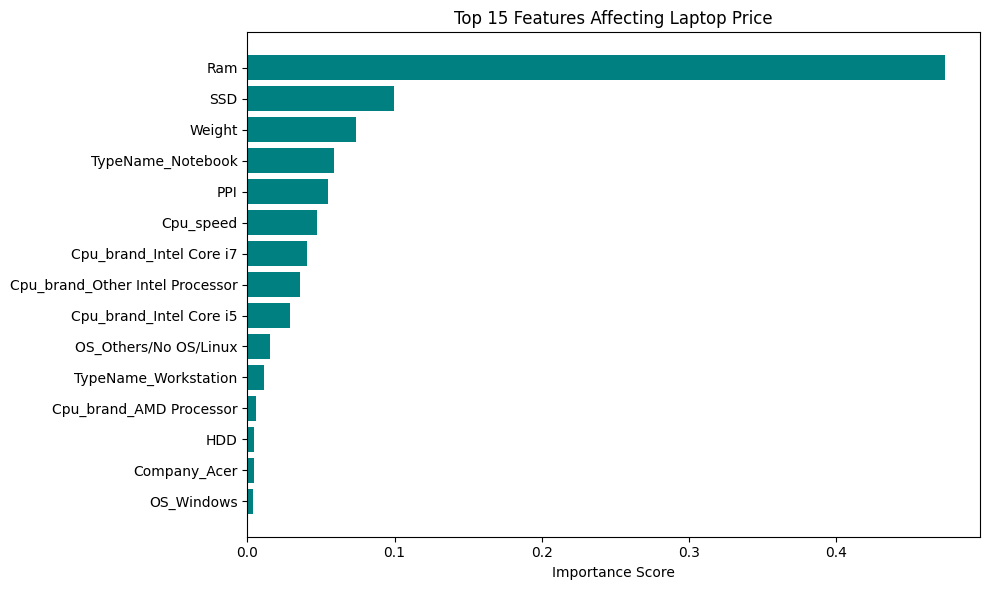

In [138]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Preprocessor se saare transformed column names nikalein
feature_names = best_model.named_steps['step1'].get_feature_names_out()

# Names ko clean karein ('num__' aur 'cat__' hatayein)
feature_names = [name.split('__')[1] for name in feature_names]

# 2. Trained Gradient Boosting model se importance scores nikalein
importances = best_model.named_steps['step2'].feature_importances_

# 3. DataFrame bana kar sort karein
feat_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Top 15 features print aur plot karein
print(feat_df.head(15))

plt.figure(figsize=(10, 6))
plt.barh(feat_df['Feature'].head(15)[::-1], feat_df['Importance'].head(15)[::-1], color='teal')
plt.xlabel("Importance Score")
plt.title("Top 15 Features Affecting Laptop Price")
plt.tight_layout()
plt.show()

<Axes: xlabel='Ram', ylabel='Price_euros'>

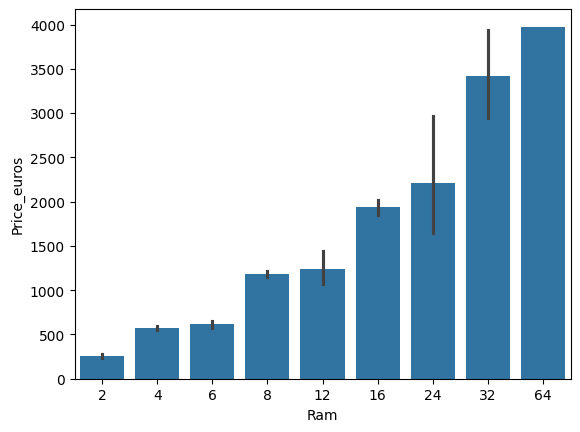

In [140]:
sns.barplot(x=df['Ram'],y=df['Price_euros'])

<Axes: xlabel='Price_euros', ylabel='Count'>

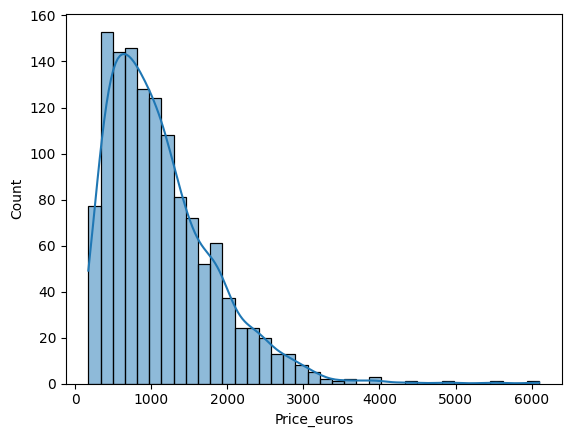

In [142]:
sns.histplot(df['Price_euros'],kde=True)

<Axes: xlabel='Company', ylabel='Price_euros'>

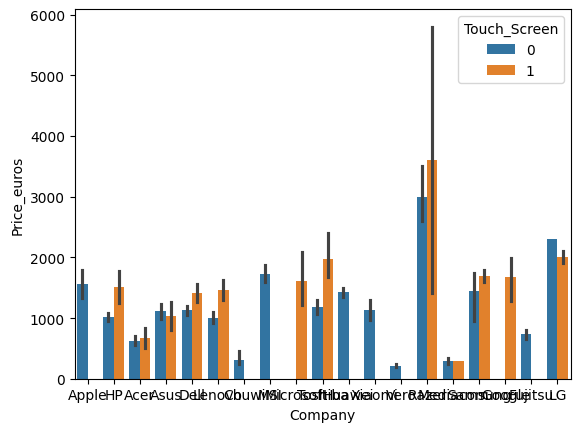

In [145]:
sns.barplot(x=df['Company'],y=df['Price_euros'],hue=df['Touch_Screen'])

<Axes: ylabel='Price_euros'>

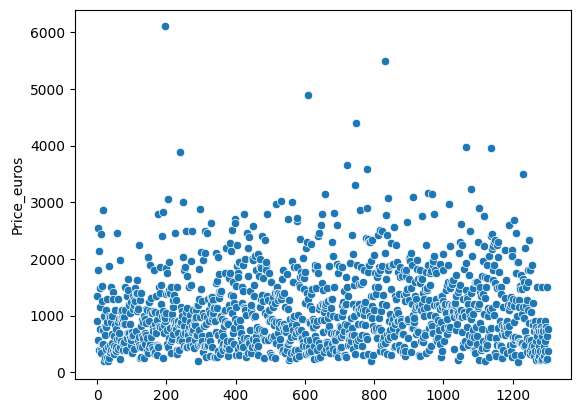

In [146]:
sns.scatterplot(df['Price_euros'])